### Name: Vrushabh Pravinbhai Bodarya
### Student_ID: REDACTED

###  (25%, coding assignment) See file NaiveBayse_MNIST_Problems.ipynb

In [1]:
# This tells matplotlib not to try opening a new window for each plot.
%matplotlib inline

# Import a bunch of libraries.
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from sklearn.pipeline import Pipeline
#from sklearn.datasets import fetch_mldata
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LinearRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, train_test_split
from sklearn.metrics import classification_report

# Set the randomizer seed so results are the same each time.
np.random.seed(0)

In [2]:
# Load the digit data either from mldata.org, or once downloaded to data_home, from disk. The data is about 53MB so this cell
# should take a while the first time your run it.
from sklearn.datasets import load_digits
mnist = load_digits()
X, Y = mnist.data, mnist.target

# Rescale grayscale values to [0,1].
X = X / 255.0

# Shuffle the input: create a random permutation of the integers between 0 and the number of data points and apply this
# permutation to X and Y.
# NOTE: Each time you run this cell, you'll re-shuffle the data, resulting in a different ordering.
shuffle = np.random.permutation(np.arange(X.shape[0]))
X, Y = X[shuffle], Y[shuffle]

print('data shape: ', X.shape)
print('label shape:', Y.shape)



# Set some variables to hold test, dev, and training data.
test_data, test_labels = X[1540:], Y[1540:]
dev_data, dev_labels = X[1400:1540], Y[1400:1540]
train_data, train_labels = X[:1400], Y[:1400]
mini_train_data, mini_train_labels = X[:200], Y[:200]

data shape:  (1797, 64)
label shape: (1797,)


### A. Create a 10x10 grid to visualize 10 examples of each digit.

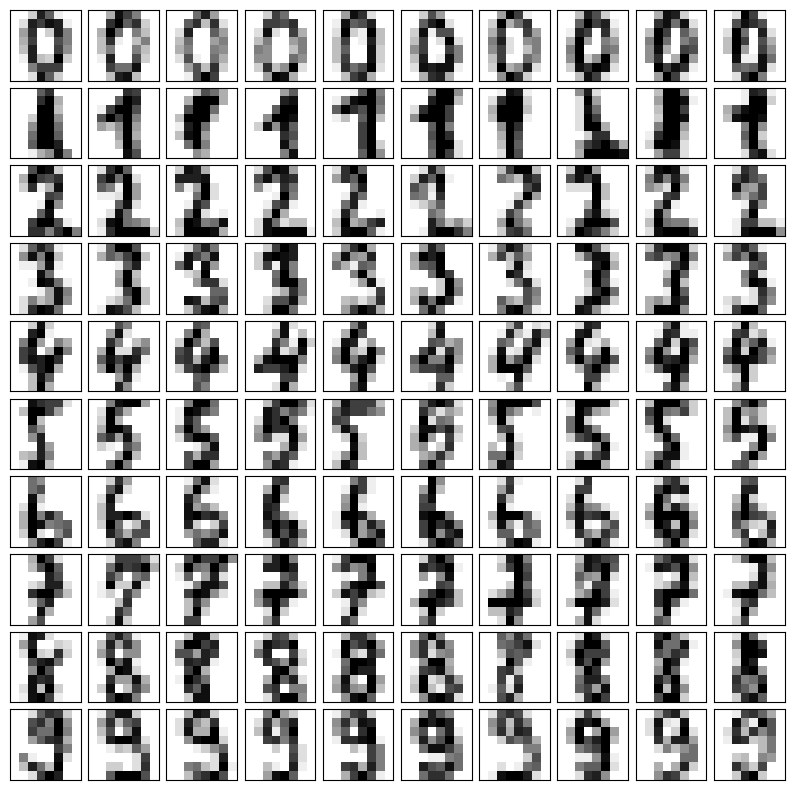

In [3]:
num_examples = 10
num_digits = 10
fig, axes = plt.subplots(num_digits, num_examples, figsize=(10, 10),
                         subplot_kw={'xticks':[], 'yticks':[]},
                         gridspec_kw=dict(hspace=0.1, wspace=0.1))

for i in range(num_digits):
    # find the indexes of the digits
    digit_indexes = np.where(Y == i)[0][:num_examples]
    for j in range(num_examples):
        # Plot each digit in the grid
        axes[i, j].imshow(X[digit_indexes[j]].reshape(8, 8), cmap='binary', interpolation='nearest')
        # Remove the axis labels
        axes[i, j].xaxis.set_visible(False)
        axes[i, j].yaxis.set_visible(False)

# Show the grid
plt.show()

### B.  Fit a Naive Bayes classifier and report accuracy on the dev data. Remember that Naive Bayes estimates P(feature|label). While sklearn can handle real-valued features, let's start by mapping the pixel values to either 0 or 1. You can do this as a preprocessing step, or with the binarize argument. With binary-valued features, you can use BernoulliNB. Next try mapping the pixel values to 0, 1, or 2, representing white, grey, or black. This mapping requires MultinomialNB. Does the multi-class version improve the results? Why or why not?
### Note, the answers may vary depending on what thresholds you set.

In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB, MultinomialNB
from sklearn.metrics import accuracy_score
import numpy as np

# Load the MNIST dataset
digits = load_digits()
X, Y = digits.data, digits.target

# Normalize pixel values to [0, 1]
X = X / 16.0

# Split the dataset into training and development sets
train_data, dev_data, train_labels, dev_labels = train_test_split(X, Y, test_size=0.2, random_state=0)

# Binarize the data for BernoulliNB
binarized_train_data = np.where(train_data > 0.5, 1, 0)  # 0.5 threshold for binarization
binarized_dev_data = np.where(dev_data > 0.5, 1, 0)

# Train Bernoulli Naive Bayes
bnb = BernoulliNB()
bnb.fit(binarized_train_data, train_labels)
bnb_predictions = bnb.predict(binarized_dev_data)
bnb_accuracy = accuracy_score(dev_labels, bnb_predictions)
print('BernoulliNB accuracy:', bnb_accuracy)

# Trinarize the data for MultinomialNB
multinomial_train_data = np.digitize(train_data, bins=[1/3, 2/3])  # Using 1/3 and 2/3 as thresholds
multinomial_dev_data = np.digitize(dev_data, bins=[1/3, 2/3])

# Train Multinomial Naive Bayes
mnb = MultinomialNB()
mnb.fit(multinomial_train_data, train_labels)
mnb_predictions = mnb.predict(multinomial_dev_data)
mnb_accuracy = accuracy_score(dev_labels, mnb_predictions)
print('MultinomialNB accuracy:', mnb_accuracy)

BernoulliNB accuracy: 0.8944444444444445
MultinomialNB accuracy: 0.9055555555555556


### Factors Influencing Performance:

1. The MNIST digits can vary not only in shape but also in stroke width and intensity. For certain digits, the pixel intensity could play a crucial role in differentiating them from others.


2. **Bernoulli Naive Bayes**:
- It works with binary features.
- Binarizing the pixel values (converting them to 0 or 1) simplifies the information to indicate whether a pixel is active or inactive.
- This approach can be highly effective if the presence or absence of a pixel serves as a strong indicator of the digit.
   
3. **Multinomial Naive Bayes**:
- It allows for a more nuanced representation.
- By mapping pixel values to 0 (white), 1 (grey), or 2 (black), you are capturing the pixel intensity, which can be essential for distinguishing between digits that have similar shapes but differ in intensity.

4. The choice of thresholds for binarizing and trinarizing the pixel values is critical. Incorrect thresholds could lead to loss of important information or inclusion of irrelevant details, affecting the classifier's accuracy.

### Potential Outcomes:

- **Improved Results**: Multinomial Naive Bayes could potentially enhance results if the pixel intensity (grey values) offers valuable extra information for differentiating between various digits.

- **Unchanged or Worse Results**: If the additional grey-scale information doesn't significantly contribute to distinguishing between the digits, or if the chosen thresholds for trinarization are not optimal, the performance might not improve and could even degrade compared to the binary approach.

### Conclusion:

The improvement, or lack thereof, when using Multinomial Naive Bayes over Bernoulli Naive Bayes largely depends on how well the chosen preprocessing method captures the relevant features of the digits for classification. Experimenting with different thresholds and analyzing the dataset's characteristics are crucial steps to identify the most effective approach.

### C. Try training a model using GuassianNB, which is intended for real-valued features, and evaluate on the dev data. You'll notice that it doesn't work so well. Could you explain why?

In [5]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Load data
digits = load_digits()
X, Y = digits.data, digits.target

# Normalize data to have values between 0 and 1
X = X / 16.0

# Split data into training and development sets
train_data, dev_data, train_labels, dev_labels = train_test_split(X, Y, test_size=0.2, random_state=0)

# Train Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(train_data, train_labels)

# Evaluate Gaussian Naive Bayes
gnb_predictions = gnb.predict(dev_data)
gnb_accuracy = accuracy_score(dev_labels, gnb_predictions)
print(f'GaussianNB Accuracy: {gnb_accuracy}')

GaussianNB Accuracy: 0.825


### Gaussian Naive Bayes might not perform well on the MNIST dataset for several reasons:

The accuracy of BernoulliNB is 0.8944 and that of MultinomialNB is 0.9056, both of which are higher than the accuracy of GaussianNB, which is approximately 0.825.

GaussianNB assumes that the features follow a normal distribution.

However, pixel values in images, particularly those in the MNIST dataset, generally do not adhere to this distribution.

GaussianNB assumes that features are independent, but in image data, adjacent pixels are typically correlated, which can impact the classifier's performance.

The variance of pixel values for different features (pixels) can vary significantly, which may not be adequately captured by a Gaussian model.
